# 04 · Trilha 3 — Mudança da escala 6x1 para 5x2

**Pergunta:** quantos integrantes a mais cada empresa precisa se a escala mudar de 6x1 para 5x2, mantendo o mesmo serviço?

**Lógica.** Para entregar o mesmo trabalho, a folha varia na razão inversa da carga semanal de cada integrante:

`folha nova / folha atual = horas semanais atuais / horas semanais novas`

Isso vale para a **folha inteira** de quem muda de escala, não só para as posições: a cobertura de ausências (Trilha 2) é proporcional à folha, então já está contida no resultado. A Trilha 3 usa a Trilha 2 para separar o adicional entre posições e cobertura, e a Trilha 1 para medir o efeito da folha maior sobre saídas e vagas.

**Resumo do que o notebook mostra:**

1. **O que muda depende da jornada, e os dados mostram que isso não é trivial.** Hoje, quem está em 6x1 trabalha 5,98 dias × 7h08 = 42,7 h/semana, e quem está em 5x2 trabalha 5,04 dias × 8h33 = 43,0 h/semana. O 5x2 praticado é a mesma carga semanal em 5 dias. Se a mudança mantiver a carga semanal, **não há adicional**. Se mantiver a jornada diária (a leitura do enunciado), a folha sobe **~20%**.
2. **Só 736 dos 4.727 ativos operacionais estão em 6x1 no cadastro** (634 na empresa 6). Outros 1.917 (empresa 5 em "Jornada 180 Mensais" e empresa 8 em "Revezamento") têm escala real desconhecida.
3. **Resultado:** adicional de **145 integrantes** (jornada diária mantida) para os 736 em 6x1, quase todos na empresa 6 (125). Se as tripulações de jornada mensal e revezamento operarem em 6x1, o teto sobe para **522**.
4. **Rotatividade:** o efeito é de segunda ordem frente ao da jornada. Os dados não permitem estimá-lo, e o notebook trata como sensibilidade.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ausencias as au, escala as es, rotatividade as rot

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})
CORTE = rot.CORTE

## 1. O que os dados dizem sobre as escalas

In [2]:
rd = lambda n, **k: pd.read_csv(f'../dados/{n}.csv', sep=';', encoding='utf-8-sig', **k)
integ = rd('dim_integrante', usecols=['ID_INTEGRANTE', 'CODCOLIGADA', 'ID_FUNCAO', 'ID_HORARIO', 'JORNADAMENSAL', 'DATAADMISSAO', 'DATADEMISSAO'],
           parse_dates=['DATAADMISSAO', 'DATADEMISSAO'])
integ = (integ.merge(rd('dim_horario', usecols=['ID_HORARIO', 'ESCALA', 'HORARIO']), on='ID_HORARIO')
              .merge(rd('dim_funcao', usecols=['ID_FUNCAO', 'FUNCAO']), on='ID_FUNCAO'))
integ['grupo'] = integ.FUNCAO.map(au.grupo_funcao)
ativos = integ[(integ.DATAADMISSAO <= CORTE) & (integ.DATADEMISSAO.isna() | (integ.DATADEMISSAO > CORTE)) & (integ.grupo != 'Aprendiz')].copy()
print(f'{len(ativos)} ativos operacionais em 30/09/2026 (sem aprendizes)')
ativos.groupby(['CODCOLIGADA', 'ESCALA']).size().unstack(0).fillna(0).astype(int)

4727 ativos operacionais em 30/09/2026 (sem aprendizes)


CODCOLIGADA,3,4,5,6,7,8
ESCALA,,,,,,
12X36,0,4,0,11,0,9
5X2,113,1,1643,81,8,161
6X1,0,1,1,634,30,70
JORNADA MENSAL,0,0,1180,0,0,0
NAO IDENTIFICADA,0,1,0,34,7,1
REVEZAMENTO,0,0,0,0,0,737


In [3]:
# jornada mensal contratada (JORNADAMENSAL esta em minutos: 13200 = 220 h/mes = 44 h/semana)
jm = ativos.assign(horas_mes=pd.to_numeric(ativos.JORNADAMENSAL, errors='coerce') / 60)
jm.groupby(['ESCALA', 'horas_mes']).size().unstack(0).fillna(0).astype(int).loc[[220, 210, 180, 125, 100]]

ESCALA,12X36,5X2,6X1,JORNADA MENSAL,NAO IDENTIFICADA,REVEZAMENTO
horas_mes,,,,,,
220.0,3,351,735,0,18,557
210.0,0,352,1,80,0,0
180.0,21,1288,0,1096,0,0
125.0,0,8,0,0,24,180
100.0,0,4,0,0,0,0


`JORNADAMENSAL` está em minutos por mês. Todos os vínculos 6x1 têm 13.200 (220 h/mês, ou 44 h/semana). Os 5x2 são, na maioria, de 180 h/mês (1.288 vínculos), com minorias de 210 h e 220 h. As "Jornada 180 Mensais" (empresa 5) têm 180 h e o revezamento da empresa 8 tem 220 h (557) ou 125 h (180).

### Dois sinais de que a escala do cadastro nem sempre é a real

In [4]:
# (a) empresa 5: tripulacoes de onibus 'em 5x2' com o mesmo horario generico
tr = ativos[(ativos.CODCOLIGADA == 5) & ativos.grupo.isin(['Motorista de ônibus', 'Cobrador'])]
a = tr.groupby(['ESCALA', 'HORARIO']).size().rename('ativos').reset_index().sort_values('ativos', ascending=False)
print('(a) empresa 5, motoristas de ônibus e cobradores:'); a.head(4)

(a) empresa 5, motoristas de ônibus e cobradores:


,ESCALA,HORARIO,ativos
0,5X2,SEG A SEX 08:00 - 12:00 | 13:12 - 18:00,1194
1,JORNADA MENSAL,Jornada 180 Mensais,1091


In [5]:
# (b) empresa 6, motorista de caminhao: demissoes com horario generico (demissoes em massa de 2023-2024)
cam = integ[(integ.CODCOLIGADA == 6) & (integ.FUNCAO == 'MOTORISTA/CAMINHAO')].assign(demitido=lambda x: x.DATADEMISSAO.notna())
b = cam.groupby('ESCALA').agg(vinculos=('demitido', 'size'), demitidos=('demitido', 'sum')); b['% demitidos'] = (b.demitidos / b.vinculos * 100).round(0)
x = cam[(cam.ESCALA == '5X2') & cam.demitido]
print('(b) empresa 6, motorista de caminhão, por escala do cadastro:'); display(b)
print('Horário dos', len(x), 'desligados em 5x2:'); x.HORARIO.value_counts().head(2)

(b) empresa 6, motorista de caminhão, por escala do cadastro:


,vinculos,demitidos,% demitidos
ESCALA,,,
5X2,828,812,98.0
6X1,938,399,43.0
NAO IDENTIFICADA,6,4,67.0


Horário dos 812 desligados em 5x2:


HORARIO
08:00 as 18:00 (12:00 | 13:12) SEG-SEX    803
05:00 AS 13:20 seg-sex PF                   3
Name: count, dtype: int64

- **(a) Empresa 5.** Os 1.194 motoristas de ônibus e cobradores "em 5x2" têm **todos o mesmo horário**, "SEG A SEX 08:00–12:00 | 13:12–18:00". É um horário-padrão de cadastro, e não a escala real de uma tripulação de ônibus. Os outros 1.091 estão em "Jornada 180 Mensais", que não informa os dias de folga. **A escala real das tripulações da empresa 5 não está nos dados.**
- **(b) Empresa 6.** Entre os motoristas de caminhão, 98% dos vínculos cadastrados em 5x2 estão desligados (812 de 828), e 803 deles têm o mesmo horário "08:00 às 18:00 SEG-SEX". É o horário atribuído nas demissões em massa de 2023–2024, não uma escala de trabalho.

Duas consequências: a escala de ~1.900 pessoas (empresas 5 e 8) precisa ser tratada como incerta, e **não dá para estimar o efeito da escala sobre a rotatividade** comparando 5x2 e 6x1 no cadastro, porque a escala dos desligados é um artefato.

## 2. Quanto cada escala realmente trabalha

In [6]:
ponto, rel = au.limpar_ponto(au.carregar_ponto('../dados'))
ponto['grupo'] = ponto.FUNCAO.map(au.grupo_funcao)
perfil = es.perfil_jornada(ponto)
res = perfil[perfil.escala.isin(['6X1', '5X2', '12X36'])].groupby('escala').agg(
    integrantes=('ID_INTEGRANTE', 'size'), dias_por_semana=('dias_sem', 'mean'), minutos_por_dia=('min_dia', 'mean'), horas_por_semana=('h_sem', 'mean'))
res.round(2)

,integrantes,dias_por_semana,minutos_por_dia,horas_por_semana
escala,,,,
12X36,27,3.49,659.43,38.34
5X2,430,5.04,513.45,43.04
6X1,976,5.98,427.95,42.68


In [7]:
# 6x1 e 5x2 por empresa e grupo (celulas com pelo menos 20 integrantes)
c = perfil[perfil.escala.isin(['6X1', '5X2'])].groupby(['empresa', 'grupo', 'escala']).agg(
    integrantes=('ID_INTEGRANTE', 'size'), dias_sem=('dias_sem', 'mean'), min_dia=('min_dia', 'mean'), h_sem=('h_sem', 'mean'))
c[c.integrantes >= 20].round(2)

integrantes  dias_sem  min_dia  h_sem
empresa grupo                        escala                                       
1       Demais                       6X1              29      5.93   440.00  43.51
3       Demais                       5X2              88      4.96   517.22  42.74
6       Demais                       5X2              78      5.04   509.97  42.72
                                     6X1              83      5.99   432.80  43.18
        Motorista (caminhão e leves) 5X2              27      5.56   473.57  43.55
                                     6X1             700      6.00   429.51  42.93
        Motorista de ônibus          6X1              23      6.00   435.78  43.59
7       Demais                       6X1              33      5.84   440.00  42.82
8       Demais                       5X2             213      5.00   520.01  43.26
                                     6X1             107      5.96   405.19  40.23

O ponto mostra a jornada praticada (só dias normais, sem férias, afastamento ou feriado):

- **6x1:** 5,98 dias por semana × 428 minutos por dia = **42,7 h/semana**.
- **5x2:** 5,04 dias por semana × 513 minutos por dia = **43,0 h/semana**.
- Na mesma empresa e função o padrão se repete: na empresa 6, funções "demais" em 6x1 trabalham 43,2 h/semana e em 5x2, 42,7 h; na 8, 40,2 h em 6x1 e 43,3 h em 5x2.

**O 5x2 que existe hoje é uma semana comprimida: mesma carga em menos dias, com dias mais longos (8h33 contra 7h08).** Por isso a pergunta "quantas pessoas a mais" não tem resposta única: depende do que acontece com a jornada.

## 3. Cenários de jornada e fator de folha

In [8]:
d6 = perfil[perfil.escala == '6X1']
dias_m, dias_lo, dias_hi = es.media_bootstrap(d6.dias_sem)
horas_m, horas_lo, horas_hi = es.media_bootstrap(d6.h_sem)
fat = es.fatores(dias_m, horas_m)
fat_lo = es.fatores(dias_lo, horas_lo); fat_hi = es.fatores(dias_hi, horas_hi)
quadro = pd.DataFrame({'fator de folha': fat}).assign(**{'aumento de folha (%)': lambda x: (x['fator de folha'] - 1) * 100})
print(f'6x1 observado: {dias_m:.2f} dias/semana (IC90% {dias_lo:.2f} a {dias_hi:.2f}) e {horas_m:.1f} h/semana')
print(f'5x2 atual (mesmos dados): {res.loc["5X2", "dias_por_semana"]:.2f} dias/semana e {res.loc["5X2", "horas_por_semana"]:.1f} h/semana')
quadro.round(3)

6x1 observado: 5.98 dias/semana (IC90% 5.98 a 5.99) e 42.7 h/semana
5x2 atual (mesmos dados): 5.04 dias/semana e 43.0 h/semana


,fator de folha,aumento de folha (%)
jornada diária mantida,1.197,19.681
limite semanal de 40 h,1.100,10.000
carga semanal mantida,1.000,0.000


| Cenário | O que acontece | Fator |
|---|---|---|
| **Jornada diária mantida** (caso base) | cada pessoa trabalha 5 dias de 7h08, em vez de 6, e a carga semanal cai de 42,7 h para ~35,7 h. É a leitura literal do enunciado ("mais folgas por integrante exige um quadro maior") | 5,98 / 5 = **1,197** (+19,7%) |
| **Limite semanal de 40 h** | a carga semanal passa de 44 h legais para 40 h | 44 / 40 = **1,10** (+10%) |
| **Carga semanal mantida** | o dia de trabalho passa para ~8h33, como já fazem os 5x2 atuais | **1,00** (sem adicional) |

O intervalo de 90% do fator do caso base (por reamostragem de integrantes) é estreito (5,98 a 5,99 dias), porque a escala 6x1 é muito regular (5,98 dias trabalhados por semana, em média, entre 976 integrantes). A incerteza relevante não é estatística: é a **definição da jornada nova**, que o enunciado não fixa. O caso base segue o enunciado. O cenário de 40 h usa os limites legais (não observados nos dados).

## 4. Quadro adicional por empresa

In [9]:
# populacao A: 6x1 no cadastro (firme). populacao B: A + escalas variaveis (jornada mensal e revezamento), tratadas como 6x1
ativos['pop_A'] = ativos.ESCALA == '6X1'
ativos['pop_B'] = ativos.ESCALA.isin(['6X1', 'JORNADA MENSAL', 'REVEZAMENTO'])
folha = pd.DataFrame({'A: 6x1 no cadastro': ativos[ativos.pop_A].groupby('CODCOLIGADA').size(),
                      'B: A + jornada mensal + revezamento': ativos[ativos.pop_B].groupby('CODCOLIGADA').size(),
                      'ativos operacionais (total)': ativos.groupby('CODCOLIGADA').size()}).fillna(0).astype(int)
folha

,A: 6x1 no cadastro,B: A + jornada mensal + revezamento,ativos operacionais (total)
CODCOLIGADA,,,
3,0,0,113
4,1,1,7
5,1,1181,2824
6,634,634,760
7,30,30,45
8,70,807,978


In [10]:
cenarios = list(fat)
linhas = []
for emp, r in folha.iterrows():
    for pop, col in (('A', 'A: 6x1 no cadastro'), ('B', 'B: A + jornada mensal + revezamento')):
        for cen in cenarios:
            linhas.append({'empresa': emp, 'populacao': pop, 'cenario': cen, 'folha_6x1': r[col],
                           'adicional': es.quadro_adicional(r[col], fat[cen]),
                           'adicional_ic_baixo': es.quadro_adicional(r[col], fat_lo[cen]), 'adicional_ic_alto': es.quadro_adicional(r[col], fat_hi[cen])})
out = pd.DataFrame(linhas)
tab = out.pivot_table(index='empresa', columns=['populacao', 'cenario'], values='adicional').round(0)
tab = tab.reindex(columns=pd.MultiIndex.from_product([['A', 'B'], cenarios]))
tab.loc['total'] = tab.sum()
tab

A                                                                   B                                             
        jornada diária mantida limite semanal de 40 h carga semanal mantida jornada diária mantida limite semanal de 40 h carga semanal mantida
empresa                                                                                                                                        
3                          0.0                    0.0                   0.0                    0.0                    0.0                   0.0
4                          0.0                    0.0                   0.0                    0.0                    0.0                   0.0
5                          0.0                    0.0                   0.0                  232.0                  118.0                   0.0
6                        125.0                   63.0                   0.0                  125.0                   63.0                   0.0
7                          6.0                    3.0                   0.0                    6.0                    3.0                   0.0
8                         14.0                    7.0                   0.0                  159.0                   81.0                   0.0
total                    145.0                   73.0                   0.0                  522.0                  265.0                   0.0

**Duas populações.** A população **A** são os vínculos com escala 6x1 no cadastro (736 ativos): é o conjunto firme. A população **B** soma a ela as 1.180 pessoas em "Jornada mensal" (empresa 5) e as 737 em "Revezamento" (empresa 8), **supondo que operem em 6x1**. Não há dado que confirme isso, então B é um teto.

Integrantes a mais (tabela acima):

| Empresa | Folha em 6x1 (A) | **A**, jornada diária mantida | A, limite de 40 h | **B**, jornada diária mantida | B, limite de 40 h |
|---|---|---|---|---|---|
| 6 | 634 | **125** | 63 | 125 | 63 |
| 8 | 70 (A) / 807 (B) | **14** | 7 | 159 | 81 |
| 7 | 30 | **6** | 3 | 6 | 3 |
| 5 | 1 (A) / 1.181 (B) | 0 | 0 | 232 | 118 |
| 3, 4 | 0 a 1 | 0 | 0 | 0 | 0 |
| **Total** | 736 (A) / 2.653 (B) | **145** | 73 | **522** | 265 |

Em **carga semanal mantida** o adicional é zero em qualquer população.

O adicional em % dos ativos operacionais da empresa: empresa 6, **16,4%**; empresa 7, 13,1%; empresa 8, 1,4% (A) a 16,2% (B); empresa 5, ~0% (A) a 8,2% (B).

In [11]:
# decomposicao do adicional (cenario 'jornada diaria mantida', populacao A) em posicoes e cobertura de ausencias (Trilha 2)
t2 = pd.read_csv('../resultados/trilha2_quadro_extra_por_empresa.csv')
t2 = t2[t2.cenario == 'base'].groupby('empresa').extra_pct.mean() / 100
perda = (t2 / (1 + t2)).rename('perda_ausencia')           # extra = perda / (1 - perda)  ->  perda = extra / (1 + extra)
dec = []
for emp, r in folha.iterrows():
    if r['A: 6x1 no cadastro'] == 0 or emp not in perda.index: continue
    d = es.decompor_adicional(r['A: 6x1 no cadastro'], fat['jornada diária mantida'], perda[emp])
    dec.append({'empresa': emp, 'folha 6x1': r['A: 6x1 no cadastro'], 'perda por ausência (T2)': perda[emp], **d,
                'adicional total': sum(d.values())})
pd.DataFrame(dec).set_index('empresa').round(2)

,folha 6x1,perda por ausência (T2),posições,cobertura de ausências,adicional total
empresa,,,,,
4,1,0.23,0.15,0.05,0.20
5,1,0.18,0.16,0.04,0.20
6,634,0.16,105.42,19.35,124.77
7,30,0.25,4.44,1.47,5.90
8,70,0.16,11.53,2.25,13.78


**Decomposição (Trilha 2).** Na empresa 6, a perda por ausência é de ~16%: dos 125 integrantes a mais (jornada diária mantida), **~105 são posições** e **~19 são cobertura de ausências**. A parte de cobertura aparece porque o fator multiplica a folha inteira, e a folha já contém os folguistas e feristas.

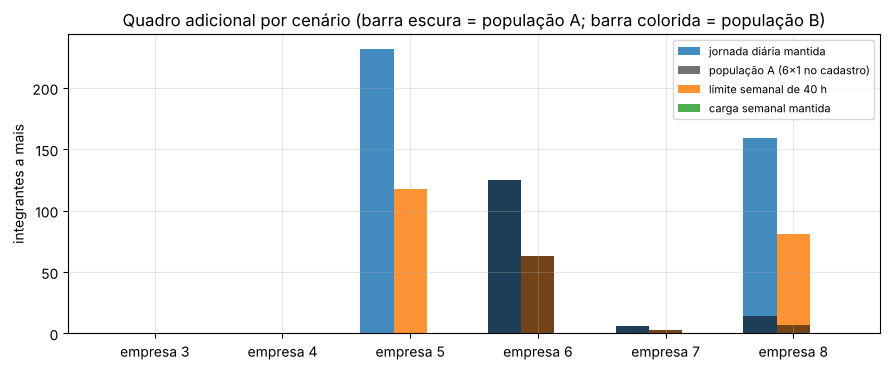

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
emps = tab.index[:-1]; x = np.arange(len(emps)); w = .26
for k, cen in enumerate(cenarios):
    ax.bar(x + (k - 1) * w, tab.loc[emps, ('B', cen)].values, w, label=cen, alpha=.85)
    ax.bar(x + (k - 1) * w, tab.loc[emps, ('A', cen)].values, w, color='k', alpha=.55, label='população A (6x1 no cadastro)' if k == 0 else None)
ax.set_xticks(x); ax.set_xticklabels([f'empresa {e}' for e in emps]); ax.set_ylabel('integrantes a mais'); ax.legend(fontsize=8)
ax.set_title('Quadro adicional por cenário (barra escura = população A; barra colorida = população B)'); plt.tight_layout(); plt.show()

## 5. Efeito na rotatividade

In [13]:
# O cadastro nao permite estimar o efeito da escala na rotatividade (secao 1). Entra como sensibilidade sobre o turnover da Trilha 1.
t1 = pd.read_csv('../resultados/trilha1_projecao.csv').set_index('empresa')['turnover_base_%']
linhas = []
for emp, r in folha.iterrows():
    if r['A: 6x1 no cadastro'] == 0 or emp not in t1.index or pd.isna(t1[emp]): continue
    for m in (0.7, 0.8, 0.9, 1.0, 1.1, 1.2):
        e = es.efeito_rotatividade(r['A: 6x1 no cadastro'], fat['jornada diária mantida'], t1[emp], m)
        linhas.append({'empresa': emp, 'multiplicador da taxa': m, **e})
rot_tab = pd.DataFrame(linhas)
rot_tab.pivot(index='empresa', columns='multiplicador da taxa', values='variação de saídas/ano').round(0)

multiplicador da taxa,0.7,0.8,0.9,1.0,1.1,1.2
empresa,,,,,,
4,-0.0,-0.0,0.0,0.0,0.0,0.0
5,-0.0,-0.0,0.0,0.0,0.0,0.0
6,-63.0,-16.0,30.0,76.0,123.0,169.0
7,-1.0,-0.0,0.0,1.0,1.0,2.0
8,-3.0,-1.0,2.0,4.0,6.0,9.0


O enunciado diz que a mudança "também pode alterar a rotatividade". **Os dados não permitem medir esse efeito** (seção 1: a escala dos desligados é um artefato de cadastro), então ele entra como sensibilidade: um multiplicador sobre a taxa de rotatividade da Trilha 1, de 0,7 a 1,2.

Com o multiplicador em 1,0 (mesma taxa), a folha maior já gera mais saídas por ano: na empresa 6 (turnover base de 61%), **+76 saídas por ano**, o que significa +76 contratações por ano para repor. Com a taxa 20% menor, o aumento cai para −16 (isto é, haveria menos saídas que hoje); com a taxa 20% maior, sobe para +169.

In [14]:
# vagas abertas em media (quantos postos ficam vagos, em equivalente de pessoas) com 30 dias para repor uma saida
rot_tab.pivot(index='empresa', columns='multiplicador da taxa', values='vagas abertas em média (depois)').round(1)

multiplicador da taxa,0.7,0.8,0.9,1.0,1.1,1.2
empresa,,,,,,
4,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0
6,26.7,30.5,34.3,38.1,41.9,45.7
7,0.3,0.3,0.4,0.4,0.4,0.5
8,1.4,1.6,1.8,2.0,2.2,2.4


**Vagas abertas em média.** Supondo 30 dias para repor cada saída (premissa nossa, os dados não permitem estimar), a empresa 6 mantém hoje ~32 vagas abertas por dia. Com a folha 20% maior e a mesma taxa, passa a ~38.

In [15]:
# comparacao de ordem de grandeza (empresa 6): adicional de quadro x vagas abertas x variacao por mudar a taxa
e6 = rot_tab[rot_tab.empresa == 6].set_index('multiplicador da taxa')
pd.DataFrame({'adicional (jornada diária mantida)': es.quadro_adicional(folha.loc[6, 'A: 6x1 no cadastro'], fat['jornada diária mantida']),
              'vagas abertas se a taxa cair 20%': e6.loc[0.8, 'vagas abertas em média (depois)'],
              'vagas abertas se a taxa subir 20%': e6.loc[1.2, 'vagas abertas em média (depois)'],
              'vagas abertas hoje': e6.loc[1.0, 'vagas abertas em média (antes)']}, index=['integrantes']).T.round(1)

,integrantes
adicional (jornada diária mantida),124.8
vagas abertas se a taxa cair 20%,30.5
vagas abertas se a taxa subir 20%,45.7
vagas abertas hoje,31.8


**Ordem de grandeza (empresa 6).** O adicional por horas é de ~125 integrantes. Mudar a taxa de rotatividade em 20% para mais ou para menos move as vagas abertas entre ~31 e ~46, ou seja, **algumas dezenas de pessoas contra 125**. Para compensar o aumento de vagas causado pela folha maior, a taxa precisaria cair ~17% (1/1,197). O efeito da rotatividade é real, mas de segunda ordem para o dimensionamento. Ele pesa mais no **custo** (admissões, treinamento), que o dimensionamento por headcount não captura.

## 6. As três trilhas juntas

In [16]:
# folha necessaria por empresa: ativos (hoje) + adicional da mudanca de escala (populacao A, jornada diaria mantida)
t1p = pd.read_csv('../resultados/trilha1_projecao.csv').set_index('empresa')
conj = pd.DataFrame({'ativos operacionais': folha['ativos operacionais (total)'],
                     'folha em 6x1 (A)': folha['A: 6x1 no cadastro'],
                     'T3: adicional (A, jornada diária mantida)': [es.quadro_adicional(v, fat['jornada diária mantida']) for v in folha['A: 6x1 no cadastro']],
                     'T3: adicional (B, jornada diária mantida)': [es.quadro_adicional(v, fat['jornada diária mantida']) for v in folha['B: A + jornada mensal + revezamento']]})
conj['T3 A em % dos ativos'] = conj['T3: adicional (A, jornada diária mantida)'] / conj['ativos operacionais'] * 100
conj['T3 B em % dos ativos'] = conj['T3: adicional (B, jornada diária mantida)'] / conj['ativos operacionais'] * 100
conj['turnover T1 (%)'] = t1p['turnover_base_%'].reindex(conj.index)
conj.round(1)

,ativos operacionais,folha em 6x1 (A),"T3: adicional (A, jornada diária mantida)","T3: adicional (B, jornada diária mantida)",T3 A em % dos ativos,T3 B em % dos ativos,turnover T1 (%)
CODCOLIGADA,,,,,,,
3,113,0,0.0,0.0,0.0,0.0,32.8
4,7,1,0.2,0.2,2.8,2.8,27.0
5,2824,1,0.2,232.4,0.0,8.2,10.2
6,760,634,124.8,124.8,16.4,16.4,61.1
7,45,30,5.9,5.9,13.1,13.1,13.6
8,978,70,13.8,158.8,1.4,16.2,28.5


A tabela reúne, por empresa, a folha atual, o adicional da Trilha 3 e o turnover da Trilha 1. A cobertura de ausências da Trilha 2 já está dentro do adicional (seção 4).

Em síntese, o quadro adicional vem de **três fontes diferentes**: **(T2)** a cobertura de ausências sobre as posições, **(T3)** a folha a mais pela mudança de escala, que multiplica a folha inteira, e **(T1)** a reposição de saídas, que cresce com a folha. As empresas **6 e 7** são as mais afetadas pela mudança de escala (16% e 13% dos ativos), e a **8** e a **5** dependem de confirmar a escala real das tripulações.

In [17]:
import os; os.makedirs('../resultados', exist_ok=True)
out.round(3).to_csv('../resultados/trilha3_quadro_adicional.csv', index=False, encoding='utf-8-sig')
rot_tab.round(3).to_csv('../resultados/trilha3_sensibilidade_rotatividade.csv', index=False, encoding='utf-8-sig')
conj.round(2).to_csv('../resultados/trilha3_resumo_por_empresa.csv', encoding='utf-8-sig')

## 7. Limitações

- **Escala real de 1.917 pessoas desconhecida.** As tripulações da empresa 5 ("Jornada 180 Mensais" e um horário-padrão de 5x2) e da empresa 8 ("Revezamento") não informam dias de folga. O resultado firme (A) as exclui, e o teto (B) as trata como 6x1. Se já trabalham 5 dias por semana, o adicional delas é zero. **É a informação que mais melhoraria este resultado.**
- **A jornada pós-mudança não é definida.** O resultado vai de 0 a +20% da folha 6x1, conforme a carga semanal. O enunciado sugere o caso base, mas é uma escolha de contrato, não um dado.
- **Rotatividade não estimável.** Sensibilidade, não previsão. O prazo para repor uma vaga (30 dias) é premissa.
- **Ausências inalteradas.** Supõe que as taxas de ausência da Trilha 2 não mudam com a escala. A comparação por escala no ponto é contaminada por horários de passagem (afastados e desligados), então não dá para testar.
- **Demanda constante nos 7 dias.** O fator 6/5 supõe que o serviço é igual todos os dias da semana. Se houver mais demanda em dias úteis, o efeito pode ser menor.
- **Quadro fixo.** Usa a folha em 6x1 de set/2026 e não projeta crescimento (a empresa 6 cresceu 47% desde jan/2025).
- **Custo de transição.** Contratar e treinar ~125 pessoas leva tempo, e isso não está modelado. Aprendizes ficam fora, como na Trilha 2.